# 01 — Validation du modèle CSTR (S1-C02)

**Objectif.** Intégrer le modèle de niveau 1 `[C_A, T]` avec `scipy.integrate.solve_ivp` pour les **deux jeux de paramètres** (benchmark de Seborg et hydrolyse de l'oxyde de propylène), établir les états stationnaires et leur stabilité, et vérifier que le moteur TypeScript reproduit ces trajectoires.

Équations (README §4.3, unités moteur : s, K, mol/L, L, g/L, J, W) :

$$\frac{dC_A}{dt} = \frac{F}{V}(C_{A,in}-C_A) - k(T)C_A,\qquad
\frac{dT}{dt} = \frac{F\rho C_p (T_{in}-T) + (-\Delta H_r)\,k(T)\,C_A V - UA\,(T-T_c)}{V\rho C_p + C_w}$$

avec $k(T)=k_0 e^{-E_a/RT}$. $C_w$ est la capacité thermique de la paroi de cuve (acier) : elle ralentit la dynamique **sans changer les états stationnaires**.

In [1]:
import sys, json
sys.path.insert(0, ".")
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path
from scipy.integrate import solve_ivp

from cstr_model import (Params, Inputs, rhs, arrhenius, UA_eff, steady_states_level1,
                        jacobian_level1, R_GAS, p_sat_water, relief_heat)
from presets_py import seborg, propylene_oxide
from pid_sim import (Pid, closed_loop, linearize, steady_state_level2, closed_loop_spectral_abscissa,
                     search_gains, max_recoverable_perturbation, step_metrics)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
GOLDEN = Path("..") / "tests" / "golden"


## 1. Les deux jeux de paramètres

In [2]:
presets = {"Seborg (benchmark)": seborg().with_(level=1),
           "Oxyde de propylène (Fogler)": propylene_oxide().with_(level=1)}
rows = []
for name, p in presets.items():
    rows.append((name, p.V, p.F, p.CAin, p.Tin, p.k0, p.EaR, p.dHr/1e3, p.UAref, p.Tc,
                 -p.dHr * p.CAin / (p.rho * p.cp)))
import pandas as pd
pd.DataFrame(rows, columns=["jeu", "V [L]", "F [L/s]", "C_A,in [mol/L]", "T_in [K]", "k0 [1/s]",
                            "Ea/R [K]", "ΔH [kJ/mol]", "UA [W/K]", "Tc [K]", "ΔT_ad [K]"]).set_index("jeu").T

jeu,Seborg (benchmark),Oxyde de propylène (Fogler)
V [L],1.000000e+02,1.000000e+02
F [L/s],1.666667e+00,5.000000e-01
"C_A,in [mol/L]",1.000000e+00,4.000000e+00
T_in [K],3.500000e+02,3.000000e+02
k0 [1/s],1.200000e+09,4.711111e+09
Ea/R [K],8.750000e+03,9.064015e+03
ΔH [kJ/mol],-5.000000e+01,-8.373601e+01
UA [W/K],8.333333e+02,5.000000e+02
Tc [K],3.000000e+02,2.850000e+02
ΔT_ad [K],2.092050e+02,8.013015e+01


## 2. États stationnaires et stabilité

Les états stationnaires du niveau 1 sont les racines de $g(T)=0$ où $C_A$ est ramené à sa valeur quasi-stationnaire $C_A(T) = \frac{F/V\,C_{A,in}}{F/V + k(T)}$. La stabilité vient des valeurs propres du jacobien (en min⁻¹).

In [3]:
for name, p in presets.items():
    print(f"=== {name} ===")
    for ca, T in steady_states_level1(p):
        ev = np.linalg.eigvals(jacobian_level1(p, [ca, T, p.Tc, 0.0])) * 60
        kind = "stable" if ev.real.max() < 0 else "INSTABLE"
        print(f"  C_A = {ca:7.4f} mol/L   T = {T:8.3f} K   valeurs propres (min⁻¹) = "
              f"{np.round(ev, 3)}   → {kind}")

=== Seborg (benchmark) ===
  C_A =  0.8773 mol/L   T =  324.475 K   valeurs propres (min⁻¹) = [-1.  +0.j -0.45+0.j]   → stable
  C_A =  0.4999 mol/L   T =  350.006 K   valeurs propres (min⁻¹) = [-1.   +0.j  0.416+0.j]   → INSTABLE
  C_A =  0.2088 mol/L   T =  369.705 K   valeurs propres (min⁻¹) = [-1.363+0.j -1.   +0.j]   → stable
=== Oxyde de propylène (Fogler) ===
  C_A =  3.6637 mol/L   T =  302.541 K   valeurs propres (min⁻¹) = [-0.292+0.j -0.189+0.j]   → stable
  C_A =  2.1608 mol/L   T =  326.836 K   valeurs propres (min⁻¹) = [-0.285+0.j  0.235+0.j]   → INSTABLE
  C_A =  0.5017 mol/L   T =  353.654 K   valeurs propres (min⁻¹) = [-0.962+0.j -0.401+0.j]   → stable


**Lecture.** Le benchmark de Seborg a trois états stationnaires : 324,5 K (stable, faible conversion), **350 K (instable, point de fonctionnement du plan)** et 369,7 K (haut). La valeur propre instable vaut $+2{,}83$ min⁻¹ pour le benchmark d'origine (sans paroi, état haut = foyer instable) ; avec la capacité thermique de paroi ajoutée au modèle elle passe à **+0,42 min⁻¹** (dynamique ≈ 7× plus lente) et l'état haut devient **stable** : la bistabilité 324,5 K / 369,7 K est visible en §3.

L'hydrolyse de l'oxyde de propylène présente aussi 3 états stationnaires, avec un point milieu instable à 326,8 K.

## 3. Trajectoires (Radau) — emballement et extinction

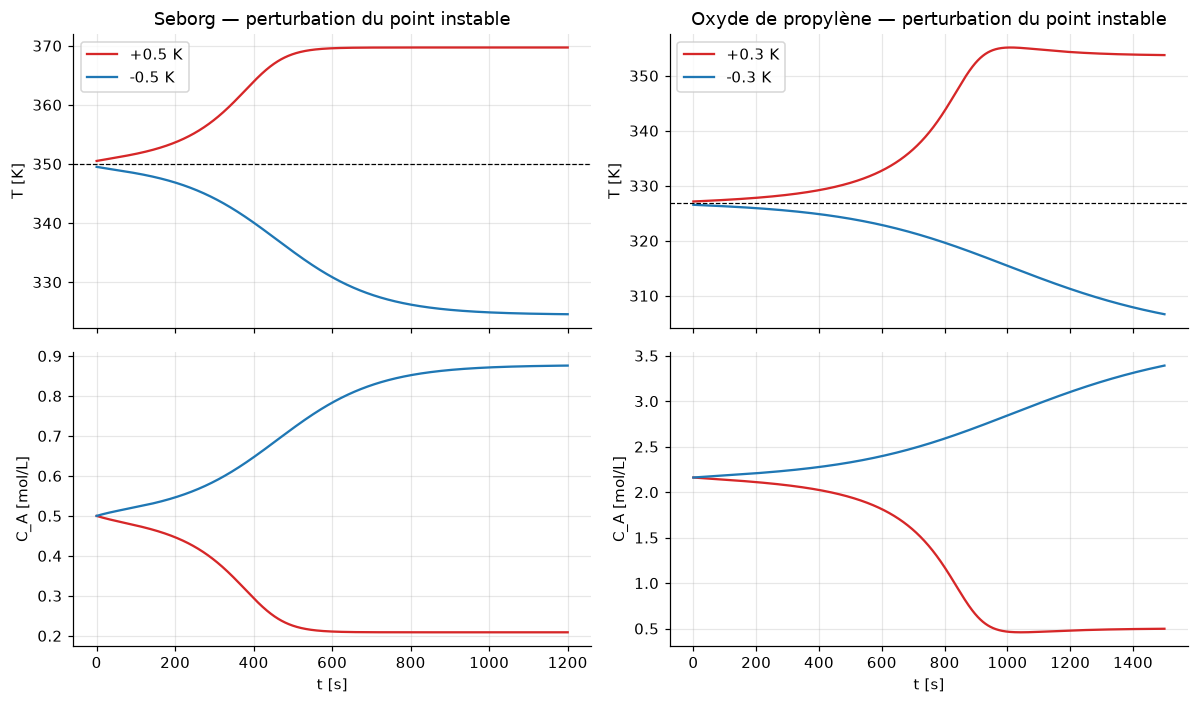

In [4]:
def traj(p, x0, t_end):
    sol = solve_ivp(lambda t, y: rhs([y[0], y[1], p.Tc, 0.0], p, Inputs())[:2], (0, t_end), x0,
                    method="Radau", rtol=1e-9, atol=1e-11, dense_output=True)
    t = np.linspace(0, t_end, 1500)
    return t, sol.sol(t)

fig, axes = plt.subplots(2, 2, figsize=(11, 6.5), sharex="col")
for col, (name, p, t_end, dT) in enumerate([
        ("Seborg", presets["Seborg (benchmark)"], 1200, 0.5),
        ("Oxyde de propylène", presets["Oxyde de propylène (Fogler)"], 1500, 0.3)]):
    ca_m, T_m = steady_states_level1(p)[1]
    for sign, color in [(+1, "tab:red"), (-1, "tab:blue")]:
        t, y = traj(p, [ca_m, T_m + sign * dT], t_end)
        axes[0, col].plot(t, y[1], color=color, label=f"{sign * dT:+.1f} K")
        axes[1, col].plot(t, y[0], color=color)
    axes[0, col].axhline(T_m, color="k", lw=0.8, ls="--")
    axes[0, col].set(title=f"{name} — perturbation du point instable", ylabel="T [K]")
    axes[1, col].set(xlabel="t [s]", ylabel="C_A [mol/L]")
    axes[0, col].legend()
fig.tight_layout()

Une perturbation de $\pm$0,3–0,5 K sur l'état instable est amplifiée : le réacteur bascule vers l'état stationnaire haut (allumage, courbes rouges) ou bas (extinction, courbes bleues). C'est la multiplicité d'états stationnaires.

## 4. Plan de phase (Seborg)

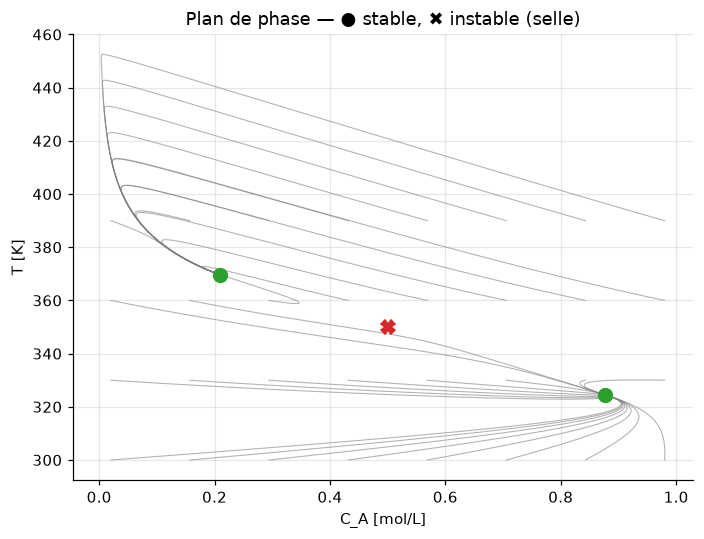

In [5]:
p = presets["Seborg (benchmark)"]
fig, ax = plt.subplots(figsize=(6.5, 5))
for ca0 in np.linspace(0.02, 0.98, 8):
    for T0 in (300, 330, 360, 390):
        sol = solve_ivp(lambda t, y: rhs([y[0], y[1], p.Tc, 0.0], p, Inputs())[:2], (0, 2500),
                        [ca0, T0], method="LSODA", rtol=1e-8, atol=1e-10)
        ax.plot(sol.y[0], sol.y[1], lw=0.7, alpha=0.6, color="tab:gray")
for (ca, T), mk in zip(steady_states_level1(p), ["o", "X", "o"]):
    ax.plot(ca, T, mk, ms=9, color="tab:red" if mk == "X" else "tab:green")
ax.set(xlabel="C_A [mol/L]", ylabel="T [K]", title="Plan de phase — ● stable, ✖ instable (selle)")
fig.tight_layout()

## 5. Vérification croisée avec le moteur TypeScript

`export_golden.py` écrit des trajectoires SciPy de référence dans `tests/golden/`. Le test Vitest `golden.test.ts` rejoue chacune avec le moteur RK4 (pas 0,01 s) et exige une erreur relative sur T inférieure à 0,5 % (exigence du plan) — l'écart réel mesuré est **< 3·10⁻⁸**. Ci-dessous, une re-simulation indépendante avec Radau rejoue les fichiers golden (contrôle de l'intégrateur de référence lui-même).

In [6]:
import warnings
rows = []
for f in sorted(GOLDEN.glob("*.json")):
    g = json.loads(f.read_text())
    P = g["params"]
    if g["preset"] == "seborg":
        base = seborg()
    else:
        base = propylene_oxide()
    p = base.with_(level=P["modelLevel"], rpm=P["rpm"], F=P["feedFlowLps"])
    u = Inputs(valve_cmd=g["valveCmd"])
    events = sorted((e["t"], e["set"]) for e in g["events"])
    x = np.array([g["initialState"][k] for k in ("CA", "T", "Tj", "v")])
    t_grid = np.array(g["t"]); T_ref = np.array(g["T"]); out = [x[1]]
    t_prev, ei = 0.0, 0
    inv = {"pumpEfficiency": "pump_eff", "fouling": "fouling", "inhibitorFactor": "inhibitor", "feedFactor": "feed_factor"}
    for tg in t_grid[1:]:
        while ei < len(events) and events[ei][0] <= t_prev + 1e-12:
            for k, v in events[ei][1].items(): setattr(u, inv[k], v)
            ei += 1
        seg_end = tg
        if ei < len(events) and events[ei][0] < tg:
            # intégrer jusqu'à l'événement puis continuer
            sol = solve_ivp(lambda tt, y: rhs(y, p, u), (t_prev, events[ei][0]), x, method="Radau", rtol=1e-10, atol=1e-12)
            x = sol.y[:, -1]; t_prev = events[ei][0]
            for k, v in events[ei][1].items(): setattr(u, inv[k], v)
            ei += 1
        sol = solve_ivp(lambda tt, y: rhs(y, p, u), (t_prev, seg_end), x, method="Radau", rtol=1e-10, atol=1e-12)
        x = sol.y[:, -1]; t_prev = seg_end; out.append(x[1])
    err = np.max(np.abs(np.array(out) - T_ref) / T_ref)
    rows.append((g["name"], g["preset"], len(t_grid), T_ref.max(), err))
pd.DataFrame(rows, columns=["trajectoire", "preset", "points", "T max [K]", "écart relatif Radau vs LSODA"])

,trajectoire,preset,points,T max [K],écart relatif Radau vs LSODA
0,l1_cold_start,seborg,601,324.250443,4.941924e-12
1,l1_open_loop_minus_half_kelvin,seborg,901,349.500000,1.513842e-10
2,l1_open_loop_plus_half_kelvin,seborg,901,369.704769,7.425706e-11
3,l2_feed_perturbation,seborg,241,350.000000,4.340599e-11
4,l2_fouling_step,seborg,91,394.491829,3.992382e-11
5,l2_low_agitation,seborg,91,393.777101,4.958573e-11
6,l2_pump_failure,seborg,91,409.845097,4.026631e-11
7,po_l1_extinction,propyleneOxide,1501,326.535624,1.344527e-10
8,po_l1_ignition,propyleneOxide,1501,355.134430,1.062538e-09
9,po_l2_pump_failure,propyleneOxide,901,377.182006,1.400697e-10
